# What did your MLP actually learn?

**AI 4200, Week 8.2 (Thursday, Oct 22).** This notebook reproduces the numbers and figures on the lecture board
*What did your MLP actually learn?*: over- and underfitting curves, the map of models, memorizing shuffled labels,
double descent with random features, the minimum-norm fit, gradient descent on 20% wrong labels, the shift test,
"every weight has an address", pixel permutation, and shift and scale augmentation.

**To run it** you need NumPy, SciPy and matplotlib (all preinstalled on Colab). The first code cell downloads about
5 MB of MNIST digits from the npm registry. There is no PyTorch and no GPU: every network is a small NumPy MLP trained
on the CPU, and the whole notebook takes about 7 minutes on 2 cores.

**Data.** The 10,000 digits bundled in the npm package [`mnist` 1.1.0](https://www.npmjs.com/package/mnist), a subset of
MNIST. A fixed shuffle (seed 0) splits them into 8,000 training and 2,000 test digits, so "test accuracy" means these
2,000 digits, not the official MNIST test set.

**Where the numbers come from.** Everything is computed here, with the seeds, epochs and learning rates used for the
slides. Closed-form and float64 results reproduce the slides exactly. The float32 network runs land within about 1–3
points of the slides (rounding in float32 differs between NumPy/BLAS builds and compounds over thousands of AdamW steps);
each section states the slide value next to this notebook's. Slides with no computation behind them are noted where
they occur.

**Notation.** ŷ are logits (one row of Ŷ per example, Ŷ = XWᵀ + b), p̂ = softmax(ŷ) are predicted probabilities and
p is the one-hot true label. For softmax + cross-entropy averaged over a batch, ∂L/∂Ŷ = (P̂ − P) / batch size.

## Setup: data

Each JSON file in the package holds `{"data": [...]}` for one digit class: all its images as one flat list of values in 0..1, 784 per image. We stack the classes,
shuffle once with `default_rng(0)`, and keep the first 8,000 digits for training and the last 2,000 for testing.
The networks train in float32. Sections 1 and 5 use a float64 copy of the same split, parsed directly from the JSON.

In [1]:
import io
import json
import os
import tarfile
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial import legendre
from scipy.ndimage import affine_transform

MNIST_URL = "https://registry.npmjs.org/mnist/-/mnist-1.1.0.tgz"
DATA_DIR = "mnist_npm"
DIGITS_DIR = os.path.join(DATA_DIR, "package", "src", "digits")


def download_digits():
    """Download the npm tarball once and extract only package/src/digits/0.json ... 9.json."""
    if all(os.path.exists(os.path.join(DIGITS_DIR, f"{d}.json")) for d in range(10)):
        return
    with urllib.request.urlopen(MNIST_URL) as response:
        tarball = io.BytesIO(response.read())
    with tarfile.open(fileobj=tarball, mode="r:gz") as archive:
        members = [m for m in archive.getmembers()
                   if m.isfile() and m.name.startswith("package/src/digits/") and m.name.endswith(".json")]
        try:
            archive.extractall(DATA_DIR, members=members, filter="data")
        except TypeError:   # older Python without the `filter` argument
            archive.extractall(DATA_DIR, members=members)


def load_digits(dtype):
    """All 10,000 digits as an (n, 784) array of the given dtype, with labels, in class order 0..9."""
    images, labels = [], []
    for digit in range(10):
        with open(os.path.join(DIGITS_DIR, f"{digit}.json")) as f:
            rows = json.load(f)["data"]
        digit_images = np.asarray(rows, dtype=dtype).reshape(-1, 784)   # stored as one flat list per class
        images.append(digit_images)
        labels.append(np.full(len(digit_images), digit))
    return np.concatenate(images), np.concatenate(labels)


download_digits()
X_all, y_all = load_digits(np.float32)
order = np.random.default_rng(0).permutation(len(X_all))
X_all, y_all = X_all[order], y_all[order]
X_train, y_train = X_all[:8000], y_all[:8000]
X_test, y_test = X_all[8000:], y_all[8000:]

# float64 copy of the same split, for the one-hidden-layer MLP (section 1) and random features (section 5)
X_all64, _ = load_digits(np.float64)
X_all64 = X_all64[order]
X_train64, X_test64 = X_all64[:8000], X_all64[8000:]

print("all digits:", X_all.shape, "per class:", np.bincount(y_all))
print("train:", X_train.shape, " test:", X_test.shape)

all digits: (10000, 784) per class: [1001 1127  991 1032  980  863 1014 1070  944  978]
train: (8000, 784)  test: (2000, 784)


## Shared helpers: plotting, label noise and image transforms

Defined once and used throughout: the slide colours, a helper to draw a digit, label corruption, and the three ways
we move pixels around — **shift** (translate with zero fill), **permute** (send every pixel to a fixed new spot) and
**scale** (resize about the image centre). The two augmentations draw a fresh random shift or scale for every image in
every batch.

In [2]:
# Slide colours
BLUE = "#2557D6"
ORANGE = "#C2510F"
INK = "#16181D"
GREY = "#8E94A0"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#E6E8EB",
    "lines.linewidth": 2,
})


def show_digit(ax, image, title=None, cmap="Greys", **imshow_kwargs):
    """Draw one 784-pixel image as 28x28 on `ax`, without ticks or grid."""
    ax.imshow(np.reshape(image, (28, 28)), cmap=cmap, **imshow_kwargs)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    if title:
        ax.set_title(title, fontsize=9)


def corrupt_labels(labels, fraction, seed):
    """Move a random `fraction` of labels to a random *wrong* class; returns (new labels, corrupted mask)."""
    rng = np.random.default_rng(seed)
    corrupted = rng.random(len(labels)) < fraction
    noisy = labels.copy()
    # adding 1..9 (mod 10) guarantees the new class differs from the true one
    noisy[corrupted] = (labels[corrupted] + rng.integers(1, 10, corrupted.sum())) % 10
    return noisy, corrupted


def shift(images, dx, dy):
    """Move 28x28 images right by dx and down by dy pixels (negative = left/up), filling with zeros."""
    grid = images.reshape(-1, 28, 28)
    out = np.zeros_like(grid)
    src_cols = slice(max(0, -dx), 28 - max(0, dx))
    dst_cols = slice(max(0, dx), 28 - max(0, -dx))
    src_rows = slice(max(0, -dy), 28 - max(0, dy))
    dst_rows = slice(max(0, dy), 28 - max(0, -dy))
    out[:, dst_rows, dst_cols] = grid[:, src_rows, src_cols]
    return out.reshape(-1, 784)


def random_translate(images, k, rng):
    """'Pad k and randomly re-crop': shift each image by its own random dx, dy in [-k, k]."""
    out = np.empty_like(images)
    dxs = rng.integers(-k, k + 1, len(images))
    dys = rng.integers(-k, k + 1, len(images))
    # shift all images that drew the same offset in one call
    for dx in range(-k, k + 1):
        for dy in range(-k, k + 1):
            same_offset = (dxs == dx) & (dys == dy)
            if same_offset.any():
                out[same_offset] = shift(images[same_offset], dx, dy)
    return out


def permute_pixels(images, perm):
    """Send pixel perm[j] to position j in every image (one fixed shuffle of the 784 pixels)."""
    return images[:, perm]


CENTRE = np.array([13.5, 13.5])


def scale(image, factor):
    """Resize one digit by `factor` about the image centre (bilinear, zero fill), keeping 28x28."""
    inverse = np.eye(2) / factor   # affine_transform maps output coordinates back to input coordinates
    resized = affine_transform(image.reshape(28, 28), inverse, offset=CENTRE - inverse @ CENTRE,
                               order=1, mode="constant", cval=0.0)
    return resized.reshape(784)


def scale_all(images, factor):
    """Resize every image by the same factor."""
    return np.stack([scale(image, factor) for image in images]).astype(np.float32)


def shift_augment(X_batch, rng):
    """Training-time augmentation: a random translation of up to 3 px on each axis."""
    return random_translate(X_batch, 3, rng)


def scale_augment(X_batch, rng):
    """Training-time augmentation: rescale each image by a random factor in [0.8, 1.2]."""
    factors = rng.uniform(0.8, 1.2, len(X_batch))
    return np.stack([scale(image, f) for image, f in zip(X_batch, factors)]).astype(np.float32)

## The model: a residual MLP in NumPy

Every MNIST experiment from section 3 on uses this network: 784 → 256 (ReLU), two residual blocks
h ← h + W_b ReLU(W_a h + b_a) + b_b, then 256 → 10 logits ŷ. Weights use He initialization, and each residual
branch's output matrix W_b is scaled by 0.1 so the forward variance stays near 1. Training is AdamW (lr 1e-3,
β = (0.9, 0.999), decoupled weight decay 1e-4), batch 128, 20 epochs unless stated otherwise. The backward pass is
written out by hand so you can match each line to the chain rule from lecture.

In [3]:
HIDDEN = 256


def he_normal(rng, fan_in, shape):
    """He initialization: N(0, 2 / fan_in), stored as float32."""
    return (rng.standard_normal(shape) * np.sqrt(2.0 / fan_in)).astype(np.float32)


def init_params(seed):
    """Initial weights of the residual MLP as a dict of float32 arrays (W has shape out x in)."""
    rng = np.random.default_rng(seed)
    params = {"W0": he_normal(rng, 784, (HIDDEN, 784)), "b0": np.zeros(HIDDEN, np.float32)}
    for block in (1, 2):
        params[f"Wa{block}"] = he_normal(rng, HIDDEN, (HIDDEN, HIDDEN))
        params[f"ba{block}"] = np.zeros(HIDDEN, np.float32)
        # a small residual-branch output keeps the forward variance near 1
        params[f"Wb{block}"] = (he_normal(rng, HIDDEN, (HIDDEN, HIDDEN)) * 0.1).astype(np.float32)
        params[f"bb{block}"] = np.zeros(HIDDEN, np.float32)
    params["Wo"] = (rng.standard_normal((10, HIDDEN)) * np.sqrt(1.0 / HIDDEN)).astype(np.float32)
    params["bo"] = np.zeros(10, np.float32)
    return params


def forward(params, X):
    """Logits Ŷ for a batch X (n x 784), plus the cache of activations the backward pass needs."""
    cache = {"X": X}
    a0 = X @ params["W0"].T + params["b0"]
    h = np.maximum(a0, 0)
    cache["a0"] = a0
    for block in (1, 2):
        u = h @ params[f"Wa{block}"].T + params[f"ba{block}"]
        r = np.maximum(u, 0)
        cache[f"h_in{block}"], cache[f"u{block}"], cache[f"r{block}"] = h, u, r
        h = h + r @ params[f"Wb{block}"].T + params[f"bb{block}"]   # residual connection
    cache["h"] = h
    y_hat = h @ params["Wo"].T + params["bo"]
    return y_hat, cache


def backward(params, cache, d_y_hat):
    """Gradients of the loss for every parameter, given ∂L/∂Ŷ."""
    grads = {}
    grads["Wo"] = d_y_hat.T @ cache["h"]
    grads["bo"] = d_y_hat.sum(0)
    dh = d_y_hat @ params["Wo"]
    for block in (2, 1):
        grads[f"Wb{block}"] = dh.T @ cache[f"r{block}"]
        grads[f"bb{block}"] = dh.sum(0)
        dr = dh @ params[f"Wb{block}"]
        du = dr * (cache[f"u{block}"] > 0)          # ReLU passes gradient only where u > 0
        grads[f"Wa{block}"] = du.T @ cache[f"h_in{block}"]
        grads[f"ba{block}"] = du.sum(0)
        dh = dh + du @ params[f"Wa{block}"]        # skip path + branch path
    da0 = dh * (cache["a0"] > 0)
    grads["W0"] = da0.T @ cache["X"]
    grads["b0"] = da0.sum(0)
    return grads


def softmax(y_hat):
    """Row-wise p̂ = softmax(ŷ); subtracting the row max avoids overflow and does not change the result."""
    z = y_hat - y_hat.max(axis=1, keepdims=True)
    p_hat = np.exp(z)
    return p_hat / p_hat.sum(axis=1, keepdims=True)


def one_hot(labels, dtype):
    """One-hot rows p for integer labels."""
    p = np.zeros((len(labels), 10), dtype)
    p[np.arange(len(labels)), labels] = 1
    return p


def adamw_update(params, grads, m, v, step, lr, weight_decay):
    """One AdamW step, in place: Adam on the gradient plus decoupled weight decay."""
    for name in params:
        m[name] = 0.9 * m[name] + 0.1 * grads[name]
        v[name] = 0.999 * v[name] + 0.001 * grads[name] ** 2
        m_hat = m[name] / (1 - 0.9 ** step)
        v_hat = v[name] / (1 - 0.999 ** step)
        params[name] -= lr * (m_hat / (np.sqrt(v_hat) + 1e-8) + weight_decay * params[name])


def train(params, X, labels, epochs=20, batch_size=128, lr=1e-3, weight_decay=1e-4, seed=0,
          augment=None, perm=None, on_epoch_end=None):
    """Train `params` in place with AdamW on softmax cross-entropy and return them.

    augment(X_batch, rng) transforms each batch; perm permutes the pixels of each batch;
    on_epoch_end(epoch, params) is called after every epoch (for tracking accuracy).
    """
    rng = np.random.default_rng(seed)      # one generator for batch order and augmentation
    m = {name: np.zeros_like(w) for name, w in params.items()}
    v = {name: np.zeros_like(w) for name, w in params.items()}
    step = 0
    for epoch in range(1, epochs + 1):
        shuffled = rng.permutation(len(X))
        for start in range(0, len(X), batch_size):
            batch = shuffled[start:start + batch_size]
            X_batch = X[batch]
            if augment is not None:
                X_batch = augment(X_batch, rng)
            if perm is not None:
                X_batch = permute_pixels(X_batch, perm)
            y_hat, cache = forward(params, X_batch)
            p_hat = softmax(y_hat)
            p = one_hot(labels[batch], p_hat.dtype)
            d_y_hat = (p_hat - p) / len(batch)    # ∂L/∂Ŷ for softmax + mean cross-entropy
            grads = backward(params, cache, d_y_hat)
            step += 1
            adamw_update(params, grads, m, v, step, lr, weight_decay)
        if on_epoch_end is not None:
            on_epoch_end(epoch, params)
    return params


def predict(params, X):
    """Predicted class for each row of X."""
    return forward(params, X)[0].argmax(1)


def accuracy(params, X, labels):
    """Fraction of rows of X classified correctly."""
    return float((predict(params, X) == labels).mean())


def accuracy_tracker(X, labels, groups=None):
    """Return (history, record): record(epoch, params) appends train/test accuracy to history.

    groups maps a name to a boolean mask over the training set; its train accuracy is recorded too.
    """
    groups = groups or {}
    history = {"epoch": [], "train": [], "test": []}
    for name in groups:
        history[name] = []

    def record(epoch, params):
        pred = predict(params, X)
        history["epoch"].append(epoch)
        history["train"].append(float((pred == labels).mean()))
        history["test"].append(accuracy(params, X_test, y_test))
        for name, mask in groups.items():
            history[name].append(float((pred[mask] == labels[mask]).mean()))

    return history, record

## 1. Recap: over- and underfitting curves

**Slides:** *Recap: over- and underfitting curves*; *Reading the curves* (same panels, smaller).
A plain **one-hidden-layer** ReLU MLP (Adam, lr 1e-3, batch 64, no regularization, float64) in two settings:
**underfit** — 2 hidden units on all 8,000 training digits for 60 epochs; **overfit** — 512 hidden units on just
500 digits for 200 epochs, with 20% of those labels moved to a wrong class. Watch the gap: underfit train and test
error stay high together; overfit train error drops to 0 while test error turns back up.

*Flag:* the slide's alt text says train error reaches 0 at epoch 28; the plotted curve (and this run) first hits 0 at
epoch 32. The slide labels the overfit panel only "512 hidden units, 500 digits"; it is this noisy-label run.

In [4]:
def train_shallow_mlp(X, labels, hidden, epochs, lr=1e-3, batch_size=64, seed=0, every=1):
    """One-hidden-layer ReLU MLP trained with Adam; returns train/test error every `every` epochs."""
    rng = np.random.default_rng(seed)   # used for the initial weights, then for batch order
    W1 = rng.standard_normal((hidden, 784)) * np.sqrt(2 / 784)
    b1 = np.zeros(hidden)
    W2 = rng.standard_normal((10, hidden)) * np.sqrt(1 / hidden)
    b2 = np.zeros(10)
    params = [W1, b1, W2, b2]
    m = [np.zeros_like(w) for w in params]
    v = [np.zeros_like(w) for w in params]
    step = 0
    history = {"epoch": [], "train_err": [], "test_err": []}

    def error(X_eval, labels_eval):
        p_hat = softmax(np.maximum(X_eval @ W1.T + b1, 0) @ W2.T + b2)
        return float((p_hat.argmax(1) != labels_eval).mean())

    for epoch in range(epochs + 1):
        if epoch % every == 0:
            history["epoch"].append(epoch)
            history["train_err"].append(error(X, labels))
            history["test_err"].append(error(X_test64, y_test))
        if epoch == epochs:
            break
        shuffled = rng.permutation(len(X))
        for start in range(0, len(X), batch_size):
            batch = shuffled[start:start + batch_size]
            X_batch = X[batch]
            u = X_batch @ W1.T + b1
            a = np.maximum(u, 0)
            p_hat = softmax(a @ W2.T + b2)
            d_y_hat = (p_hat - one_hot(labels[batch], p_hat.dtype)) / len(batch)
            grad_W2 = d_y_hat.T @ a
            grad_b2 = d_y_hat.sum(0)
            du = (d_y_hat @ W2) * (u > 0)
            grad_W1 = du.T @ X_batch
            grad_b1 = du.sum(0)
            step += 1
            # Adam (no weight decay), updating each array in place
            for k, (w, g) in enumerate(zip(params, [grad_W1, grad_b1, grad_W2, grad_b2])):
                m[k] = 0.9 * m[k] + 0.1 * g
                v[k] = 0.999 * v[k] + 0.001 * g * g
                w -= lr * (m[k] / (1 - 0.9 ** step)) / (np.sqrt(v[k] / (1 - 0.999 ** step)) + 1e-8)
    return history


underfit = train_shallow_mlp(X_train64, y_train, hidden=2, epochs=60, every=2)
labels_500_noisy, _ = corrupt_labels(y_train[:500], 0.2, seed=7)
overfit = train_shallow_mlp(X_train64[:500], labels_500_noisy, hidden=512, epochs=200, every=4)

# the slide shows the overfit run from epoch 4 to epoch 80
window = [i for i, e in enumerate(overfit["epoch"]) if 4 <= e <= 80]
epochs_shown = [overfit["epoch"][i] for i in window]
train_err_shown = [100 * overfit["train_err"][i] for i in window]
test_err_shown = [100 * overfit["test_err"][i] for i in window]
best = int(np.argmin(test_err_shown))
first_zero = epochs_shown[train_err_shown.index(0.0)]

print(f"underfit: final train error {100 * underfit['train_err'][-1]:.1f}%, test error {100 * underfit['test_err'][-1]:.1f}%")
print(f"overfit:  best test error {test_err_shown[best]:.1f}% at epoch {epochs_shown[best]}, "
      f"test error at epoch 80 {test_err_shown[-1]:.1f}%, train error first 0 at epoch {first_zero}")

underfit: final train error 36.8%, test error 39.5%
overfit:  best test error 19.6% at epoch 4, test error at epoch 80 24.6%, train error first 0 at epoch 32


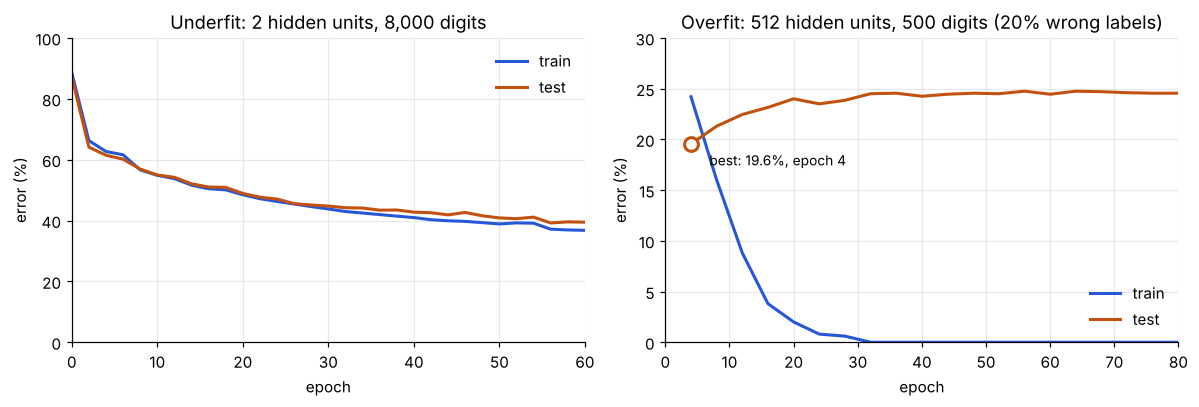

In [5]:
fig, (ax_under, ax_over) = plt.subplots(1, 2, figsize=(11, 3.8))
ax_under.plot(underfit["epoch"], 100 * np.array(underfit["train_err"]), color=BLUE, label="train")
ax_under.plot(underfit["epoch"], 100 * np.array(underfit["test_err"]), color=ORANGE, label="test")
ax_under.set(title="Underfit: 2 hidden units, 8,000 digits", xlabel="epoch", ylabel="error (%)",
             xlim=(0, 60), ylim=(0, 100))

ax_over.plot(epochs_shown, train_err_shown, color=BLUE, label="train")
ax_over.plot(epochs_shown, test_err_shown, color=ORANGE, label="test")
ax_over.plot(epochs_shown[best], test_err_shown[best], "o", ms=9, mfc="white", mec=ORANGE, mew=2)
ax_over.annotate(f"best: {test_err_shown[best]:.1f}%, epoch {epochs_shown[best]}",
                 (epochs_shown[best], test_err_shown[best]), xytext=(12, -14), textcoords="offset points", fontsize=9)
ax_over.set(title="Overfit: 512 hidden units, 500 digits (20% wrong labels)", xlabel="epoch", ylabel="error (%)",
            xlim=(0, 80), ylim=(0, 30))
for ax in (ax_under, ax_over):
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 2. A map of models (click *Next run*)

**Slide:** *A map of models*, titled *Why does this happen?* on the board. Each click is one training run, drawn as a
fitted curve. Runs 1–4 are the **underfit** class: a straight line fit to 10 points on a parabola by plain gradient
descent (5 steps of lr 0.3 from a random start) — every run fails on train and test alike. Runs 5–14 are the
**overfit** class: a degree-15 Legendre polynomial (16 weights) through 10 points on a noisy line. There are infinitely
many exact fits; gradient descent from a start w₀ converges to the exact fit nearest w₀, which is
w₀ + V⁺(y − Vw₀) with V the design matrix. We draw 4,000 random starts and show 2 that also fit the test points and 8
that do not, in the slide's order. Notice every overfit run has train MSE 0, yet test MSE varies widely.

In [6]:
def mse(prediction, target):
    """Mean squared error."""
    return float(np.mean((prediction - target) ** 2))


def underfit_runs():
    """Four short gradient-descent runs of a line fit to points on a parabola."""
    rng = np.random.default_rng(3)
    x_fit = np.linspace(-0.9, 0.9, 10) + rng.uniform(-0.04, 0.04, 10)
    x_check = np.linspace(-0.8, 0.8, 9) + rng.uniform(-0.04, 0.04, 9)
    y_fit = x_fit ** 2 + rng.normal(0, 0.05, 10)
    y_check = x_check ** 2 + rng.normal(0, 0.05, 9)
    A = np.stack([np.ones_like(x_fit), x_fit], 1)          # columns: intercept, slope
    A_check = np.stack([np.ones_like(x_check), x_check], 1)
    least_squares = np.linalg.lstsq(A, y_fit, rcond=None)[0]
    print("least-squares line: train MSE", round(mse(A @ least_squares, y_fit), 3),
          "test MSE", round(mse(A_check @ least_squares, y_check), 3))
    starts = np.random.default_rng(11)
    runs = []
    for _ in range(4):
        w = starts.normal(0, 0.6, 2)
        for _ in range(5):
            w -= 0.3 * 2 * A.T @ (A @ w - y_fit) / len(y_fit)   # lr 0.3 times the MSE gradient
        runs.append({"w": w, "train": round(mse(A @ w, y_fit), 3), "test": round(mse(A_check @ w, y_check), 3)})
    return runs, (x_fit, y_fit, x_check, y_check)


def overfit_runs(n_starts=4000, good_threshold=0.06):
    """Exact degree-15 fits reached from random starts; returns 2 good and 8 bad ones in slide order."""
    rng = np.random.default_rng(143)
    x_fit = np.linspace(-0.9, 0.9, 10)
    x_check = (x_fit[:-1] + x_fit[1:]) / 2
    y_fit = 0.6 * x_fit + rng.normal(0, 0.15, 10)
    y_check = 0.6 * x_check + rng.normal(0, 0.15, 9)
    V = legendre.legvander(x_fit, 15)
    V_check = legendre.legvander(x_check, 15)
    V_pinv = np.linalg.pinv(V)
    grid = np.linspace(-0.97, 0.97, 97)
    V_grid = legendre.legvander(grid, 15)

    starts = np.random.default_rng(5)
    candidates = []
    for _ in range(n_starts):
        w0 = starts.normal(0, 1.0, 16)
        w = w0 + V_pinv @ (y_fit - V @ w0)   # where gradient descent from w0 converges
        candidates.append({"test": mse(V_check @ w, y_check), "train": mse(V @ w, y_fit), "curve": V_grid @ w})
    test_mse = np.array([c["test"] for c in candidates])
    line_test = mse(np.polyval(np.polyfit(x_fit, y_fit, 1), x_check), y_check)
    print("plain line: test MSE", round(line_test, 3))
    print(f"random starts with test MSE < {good_threshold}: {(test_mse < good_threshold).mean():.3f}; "
          f"median test MSE {np.median(test_mse):.3f}")

    good = [c for c in candidates if c["test"] < good_threshold][:2]
    # 'bad' fits: clearly worse on test, but still drawable on the slide's axes
    bad = [c for c in candidates if c["test"] > 0.12 and np.abs(c["curve"]).max() < 2.5][:8]
    slide_order = "bbbgbbbbgb"
    runs = []
    for kind in slide_order:
        c = good.pop(0) if kind == "g" else bad.pop(0)
        runs.append({"curve": c["curve"], "train": round(c["train"], 4), "test": round(c["test"], 3),
                     "good": kind == "g"})
    return runs, grid, (x_fit, y_fit, x_check, y_check)


under, under_data = underfit_runs()
over, over_grid, over_data = overfit_runs()
print("underfit runs (train MSE, test MSE):", [(r["train"], r["test"]) for r in under])
print("overfit runs (train MSE, test MSE, fits test?):", [(r["train"], r["test"], r["good"]) for r in over])

least-squares line: train MSE 0.083 test MSE 0.067
plain line: test MSE 0.031
random starts with test MSE < 0.06: 0.101; median test MSE 0.208
underfit runs (train MSE, test MSE): [(0.109, 0.085), (0.085, 0.07), (0.086, 0.069), (0.083, 0.066)]
overfit runs (train MSE, test MSE, fits test?): [(0.0, 0.215, False), (0.0, 0.256, False), (0.0, 0.557, False), (0.0, 0.037, True), (0.0, 0.304, False), (0.0, 0.834, False), (0.0, 0.227, False), (0.0, 1.079, False), (0.0, 0.055, True), (0.0, 0.297, False)]


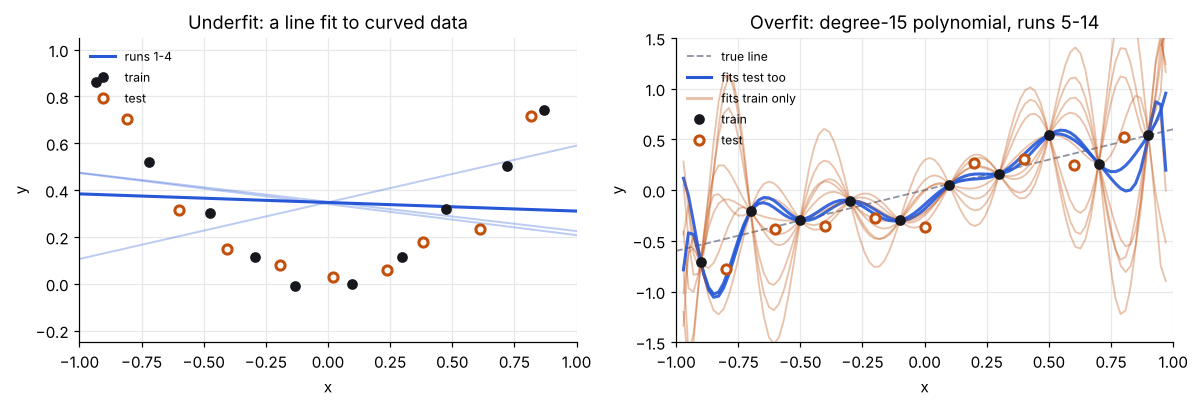

In [7]:
fig, (ax_under, ax_over) = plt.subplots(1, 2, figsize=(11, 3.8))

x_fit, y_fit, x_check, y_check = under_data
x_line = np.array([-1, 1.0])
for i, run in enumerate(under):
    last = i == len(under) - 1
    ax_under.plot(x_line, run["w"][0] + run["w"][1] * x_line, color=BLUE, alpha=1 if last else 0.3,
                  lw=2 if last else 1.3, label="runs 1-4" if last else None)
ax_under.plot(x_fit, y_fit, "o", color=INK, label="train")
ax_under.plot(x_check, y_check, "o", mfc="white", mec=ORANGE, mew=2, label="test")
ax_under.set(title="Underfit: a line fit to curved data", xlabel="x", ylabel="y", xlim=(-1, 1), ylim=(-0.25, 1.05))

x_fit, y_fit, x_check, y_check = over_data
ax_over.plot([-1, 1], [-0.6, 0.6], "--", color=GREY, lw=1.2, label="true line")
for run in over:
    ax_over.plot(over_grid, np.clip(run["curve"], -1.8, 1.8), color=BLUE if run["good"] else ORANGE,
                 alpha=0.9 if run["good"] else 0.35, lw=2 if run["good"] else 1.2)
ax_over.plot([], [], color=BLUE, label="fits test too")
ax_over.plot([], [], color=ORANGE, alpha=0.35, label="fits train only")
ax_over.plot(x_fit, y_fit, "o", color=INK, label="train")
ax_over.plot(x_check, y_check, "o", mfc="white", mec=ORANGE, mew=2, label="test")
ax_over.set(title="Overfit: degree-15 polynomial, runs 5-14", xlabel="x", ylabel="y", xlim=(-1, 1), ylim=(-1.5, 1.5))
for ax in (ax_under, ax_over):
    ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## 3. Deep nets cover almost everything; yet on real labels it works

**Slides:** *Deep nets cover almost everything* (the A/B/C prediction) and *Yet on real labels it works*.
The residual MLP has far more weights than there are training images. The 100% train / 96% test result is the
true-label run in section 4.

In [8]:
n_params = sum(w.size for w in init_params(1).values())
print(f"parameters: {n_params:,} ({n_params:.1e});  training images: {len(X_train):,};  "
      f"parameters per image: {n_params / len(X_train):.0f}")

parameters: 466,698 (4.7e+05);  training images: 8,000;  parameters per image: 58


## 4. The test: shuffle the labels → It can memorize noise

**Slides:** *A hypothesis: the data is too hard to memorize* (six training digits), *The test: shuffle the labels*,
*It can memorize noise*, *Yet on real labels it works*. Shuffling the training labels keeps the label counts but
destroys any link between image and label. The same network (init seed 1, 60 epochs) is trained once on the true
labels and once on the shuffled ones. If it reaches near-100% train accuracy on noise, the class of functions it can
represent is big enough to memorize anything — so capacity alone cannot explain why it generalizes on real labels.
(Runtime about 2 minutes.)

*Slide vs. this notebook:* shuffled labels agree with the true ones on 9.6% (here 9.55%); true labels 100% train,
96% test (here 100%, 96.0%). Random labels: slide 70% train at epoch 10, 99% at epoch 60, 9.7% test; here 69.2%, then
96.2% at epoch 60 (peak 99.3%), 8.5% test.

shuffled labels equal true labels on 0.0955 of images; label counts unchanged: True


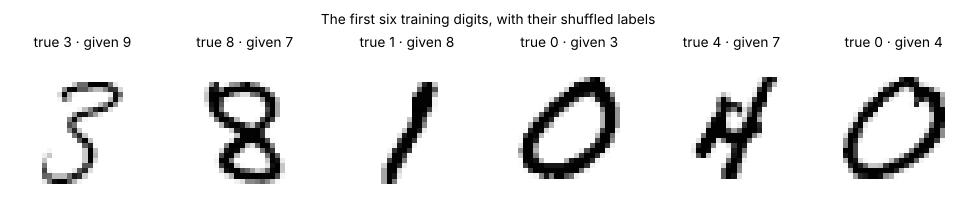

In [9]:
y_shuffled = np.random.default_rng(42).permutation(y_train)
print("shuffled labels equal true labels on", (y_shuffled == y_train).mean(), "of images;",
      "label counts unchanged:", (np.bincount(y_shuffled) == np.bincount(y_train)).all())

fig, axes = plt.subplots(1, 6, figsize=(9, 1.9))
for i, ax in enumerate(axes):
    show_digit(ax, X_train[i], f"true {y_train[i]} · given {y_shuffled[i]}", vmin=0, vmax=1)
fig.suptitle("The first six training digits, with their shuffled labels", fontsize=9)
plt.tight_layout()
plt.show()

In [10]:
true_history, record = accuracy_tracker(X_train, y_train)
params = init_params(1)
record(0, params)
train(params, X_train, y_train, epochs=60, seed=1, on_epoch_end=record)

random_history, record = accuracy_tracker(X_train, y_shuffled)
params = init_params(1)
record(0, params)
train(params, X_train, y_shuffled, epochs=60, seed=1, on_epoch_end=record)

print("epoch   true labels (train / test)   shuffled labels (train / test)")
for e in [5, 10, 20, 30, 40, 50, 60]:
    print(f"{e:5d}   {true_history['train'][e]:.3f} / {true_history['test'][e]:.3f}"
          f"               {random_history['train'][e]:.3f} / {random_history['test'][e]:.3f}")
for name, history in [("true", true_history), ("shuffled", random_history)]:
    print(f"{name} labels: max train {max(history['train'])}, mean test over the last 10 epochs "
          f"{round(sum(history['test'][-10:]) / 10, 4)}")

epoch   true labels (train / test)   shuffled labels (train / test)
    5   0.995 / 0.948               0.367 / 0.085
   10   0.997 / 0.950               0.692 / 0.080
   20   1.000 / 0.959               0.946 / 0.090
   30   1.000 / 0.959               0.968 / 0.090
   40   1.000 / 0.959               0.970 / 0.088
   50   1.000 / 0.960               0.979 / 0.083
   60   1.000 / 0.960               0.962 / 0.085
true labels: max train 1.0, mean test over the last 10 epochs 0.9597
shuffled labels: max train 0.993375, mean test over the last 10 epochs 0.0875


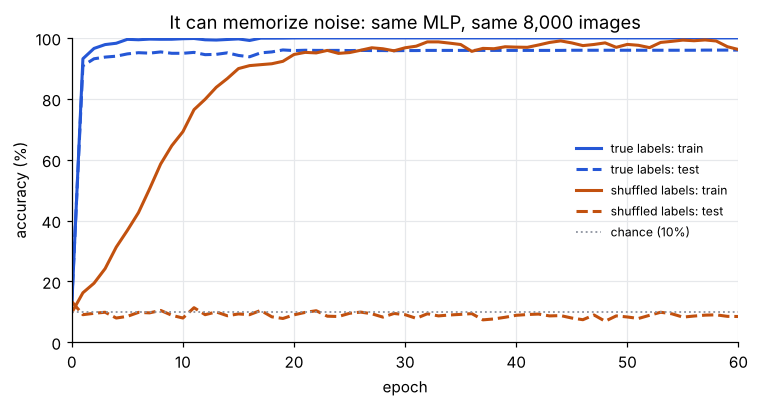

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for name, history, colour in [("true", true_history, BLUE), ("shuffled", random_history, ORANGE)]:
    ax.plot(history["epoch"], 100 * np.array(history["train"]), color=colour, label=f"{name} labels: train")
    ax.plot(history["epoch"], 100 * np.array(history["test"]), color=colour, ls="--", label=f"{name} labels: test")
ax.axhline(10, color=GREY, ls=":", lw=1.2, label="chance (10%)")
ax.set(title="It can memorize noise: same MLP, same 8,000 images", xlabel="epoch", ylabel="accuracy (%)",
       xlim=(0, 60), ylim=(0, 100))
ax.legend(frameon=False, fontsize=8, loc="center right")
plt.tight_layout()
plt.show()

## 5. Hypothesis 2: the class grows → Classical U-curve → Double descent

**Slides:** *Hypothesis 2: the class grows* is a conceptual drawing with no data. *Classical U-curve* shows the curve
below only up to p = n; *Double descent: what actually happens* shows all of it.
A **random-features** model makes the experiment cheap: a fixed random matrix V (p × 784) feeds p ReLU features, and
only the readout is fit, by least squares on the one-hot labels of n = 1,000 training digits. When p > n there are
many exact fits and `lstsq` returns the one with the smallest norm. Error is averaged over 3 random V (seeds 100–102).
Notice the spike at p = n, where the fit is forced through every point with barely enough features, and the second
descent beyond it.

In [12]:
N_FIT = 1000
FEATURE_COUNTS = [50, 100, 200, 400, 600, 800, 900, 950, 1000, 1050, 1100, 1200, 1500, 2000, 3000, 5000, 10000]


def random_features_fit(X_fit, p_fit, n_features, seed):
    """Random ReLU features F = ReLU(X Vᵀ) and the least-squares readout W (minimum-norm when p > n)."""
    V = np.random.default_rng(seed).standard_normal((n_features, 784)) / np.sqrt(784)
    F = np.maximum(X_fit @ V.T, 0)
    W, *_ = np.linalg.lstsq(F, p_fit, rcond=None)   # here F W ≈ P, so W is p x 10
    return V, W


X_fit64, labels_fit = X_train64[:N_FIT], y_train[:N_FIT]
train_err, test_err = [], []
for n_features in FEATURE_COUNTS:
    train_wrong, test_wrong = [], []
    for seed in (100, 101, 102):
        V, W = random_features_fit(X_fit64, np.eye(10)[labels_fit], n_features, seed)
        train_wrong.append((np.maximum(X_fit64 @ V.T, 0) @ W).argmax(1) != labels_fit)
        test_wrong.append((np.maximum(X_test64 @ V.T, 0) @ W).argmax(1) != y_test)
    train_err.append(100 * float(np.mean(train_wrong)))
    test_err.append(100 * float(np.mean(test_wrong)))
    print(f"p = {n_features:>6}: train error {train_err[-1]:5.1f}%   test error {test_err[-1]:5.1f}%")

p =     50: train error  24.1%   test error  30.5%


p =    100: train error  11.8%   test error  22.4%
p =    200: train error   5.6%   test error  17.4%


p =    400: train error   0.6%   test error  17.0%


p =    600: train error   0.0%   test error  20.3%


p =    800: train error   0.0%   test error  32.0%


...

p =   1500: train error   0.0%   test error  19.1%


p =   2000: train error   0.0%   test error  13.2%


p =   3000: train error   0.0%   test error  10.3%


p =   5000: train error   0.0%   test error   9.0%


p =  10000: train error   0.0%   test error   8.2%


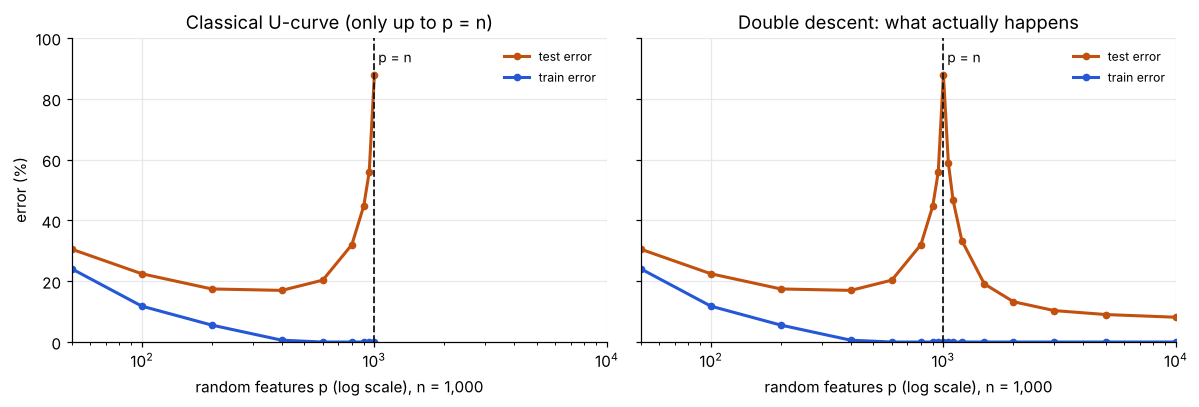

In [13]:
counts = np.array(FEATURE_COUNTS)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, largest, title in [(axes[0], 1000, "Classical U-curve (only up to p = n)"),
                           (axes[1], 10000, "Double descent: what actually happens")]:
    shown = counts <= largest
    ax.plot(counts[shown], np.array(test_err)[shown], "o-", color=ORANGE, ms=4, label="test error")
    ax.plot(counts[shown], np.array(train_err)[shown], "o-", color=BLUE, ms=4, label="train error")
    ax.axvline(N_FIT, color=INK, ls="--", lw=1.2)
    ax.text(N_FIT, 92, " p = n", fontsize=9)
    ax.set(title=title, xscale="log", xlim=(50, 10000), ylim=(0, 100),
           xlabel="random features p (log scale), n = 1,000")
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("error (%)")
plt.tight_layout()
plt.show()

## 6. Not explicit regularization

**Slide:** *Not explicit regularization* ("Maybe explicit regularization causes generalization?"). Two tests on the
residual MLP from init seed 1. **Take it away:** true labels, 40 epochs, weight decay 1e-4 vs. 0 — if weight decay were
the reason the network generalizes, removing it should hurt. **Turn it up 10×:** shuffled labels, 60 epochs, weight
decay 1e-3 — if it prevented memorization, train accuracy should stay low. Neither happens. The slide shows only these
numbers. (Runtime about 1–2 minutes.)

*Slide vs. this notebook:* test 96.1% with weight decay, 96.3% without (here 95.9%, 96.05%); shuffled labels with
10× weight decay 99.5% train, 10.8% test (here 97.6%, 9.5%). Same conclusion.

In [14]:
runs = [("true labels, weight decay 0", y_train, 40, 0.0),
        ("true labels, weight decay 1e-4", y_train, 40, 1e-4),
        ("shuffled labels, weight decay 1e-3", y_shuffled, 60, 1e-3)]
for name, labels, epochs, weight_decay in runs:
    params = train(init_params(1), X_train, labels, epochs=epochs, weight_decay=weight_decay, seed=1)
    print(f"{name:36s} train {accuracy(params, X_train, labels):.4f}   test {accuracy(params, X_test, y_test):.4f}")

true labels, weight decay 0          train 1.0000   test 0.9605


true labels, weight decay 1e-4       train 1.0000   test 0.9590


shuffled labels, weight decay 1e-3   train 0.9762   test 0.0950


## 7. What guides training? Implicit regularization: the smallest fit

**Slides:** *What guides training? (invisible hand)* is a discussion question. The data slide is *Implicit
regularization: the smallest fit*. Same random-features sweep as section 5, now recording the size ‖W‖ (Frobenius
norm) of the least-squares readout, median over the 3 seeds. Past p = n the minimum-norm fit gets *smaller* as p
grows — the solver picks the smallest of the many exact fits, and smaller fits generalize better. The features here are
built from the float32 training digits (cast to float64), so the fits differ from section 5's only in the last digits.

In [15]:
X_fit = X_train[:N_FIT].astype(np.float64)
weight_norms = []
for n_features in FEATURE_COUNTS:
    norms_per_seed = []
    for seed in (100, 101, 102):
        _, W = random_features_fit(X_fit, np.eye(10)[labels_fit], n_features, seed)
        norms_per_seed.append(float(np.linalg.norm(W)))
    weight_norms.append(float(np.median(norms_per_seed)))
    print(f"p = {n_features:>6}: ‖W‖ = {weight_norms[-1]:8.2f}")

p =     50: ‖W‖ =     5.13
p =    100: ‖W‖ =     5.70
p =    200: ‖W‖ =     7.85


p =    400: ‖W‖ =    10.27


p =    600: ‖W‖ =    17.46


p =    800: ‖W‖ =    23.29


p =    900: ‖W‖ =    37.33


...

p =   1500: ‖W‖ =    12.15


p =   2000: ‖W‖ =     8.48


p =   3000: ‖W‖ =     5.91


p =   5000: ‖W‖ =     4.13


p =  10000: ‖W‖ =     2.74


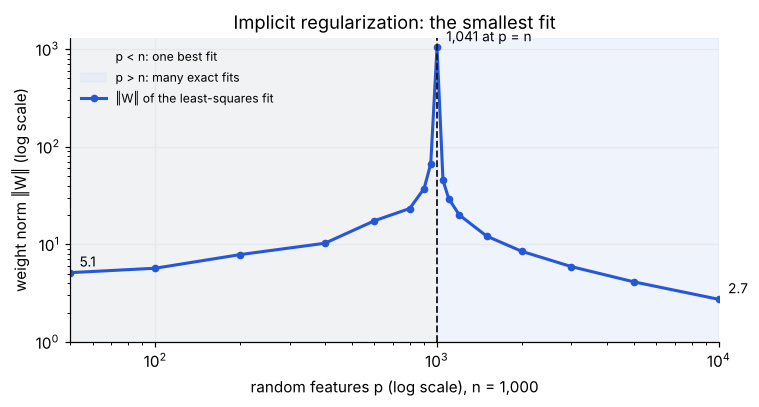

In [16]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.axvspan(50, N_FIT, color="#F1F2F4", zorder=0, label="p < n: one best fit")
ax.axvspan(N_FIT, 10000, color="#DCE5FA", alpha=0.45, zorder=0, label="p > n: many exact fits")
ax.plot(FEATURE_COUNTS, weight_norms, "o-", color=BLUE, ms=4, label="‖W‖ of the least-squares fit")
ax.axvline(N_FIT, color=INK, ls="--", lw=1.2)
for n_features in (50, 1000, 10000):
    norm = weight_norms[FEATURE_COUNTS.index(n_features)]
    text = f"{norm:,.1f}" if norm < 100 else f"{norm:,.0f} at p = n"
    ax.annotate(text, (n_features, norm), xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.set(title="Implicit regularization: the smallest fit", xscale="log", yscale="log", xlim=(50, 10000),
       ylim=(1, 1300), xlabel="random features p (log scale), n = 1,000", ylabel="weight norm ‖W‖ (log scale)")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## 8. Setup: 20% wrong labels → Gradient descent: structure first

**Slides:** *Setup: 20% wrong labels* (a prediction slide with empty axes) and *Gradient descent: structure first*.
A random 20% of the 8,000 training labels are moved to a wrong class, and the residual MLP (init seed 1) trains for
60 epochs. After every epoch we measure train accuracy separately on the correctly and the wrongly labelled digits
(against the labels the network was given), plus test accuracy. Notice the order: the shared structure is fit within
an epoch or two while the wrong labels are still predicted as their true digit; memorizing the wrong labels comes
much later and costs test accuracy. (Runtime about 1 minute.)

*Slide vs. this notebook:* epoch 1: 92% of clean labels fit, 2% of wrong ones (here 92.4%, 1.8%); best test 92.6% at
epoch 3 (here 92.55% at epoch 3); epoch 60: wrong labels 99% memorized, test 81% (here 97.6%, 77.8%).
The setup slide's five example digits (four correct, a 4 labelled 7) are hand-picked illustrations, not computed.

In [17]:
y_noisy, corrupted = corrupt_labels(y_train, 0.2, seed=7)
print(f"corrupted labels: {corrupted.mean():.1%}")

noisy_history, record = accuracy_tracker(X_train, y_noisy, groups={"clean": ~corrupted, "corrupted": corrupted})
params = init_params(1)
record(0, params)
train(params, X_train, y_noisy, epochs=60, seed=1, on_epoch_end=record)

best = int(np.argmax(noisy_history["test"]))
print("best test", round(noisy_history["test"][best], 4), "at epoch", noisy_history["epoch"][best],
      "  final test", round(noisy_history["test"][-1], 4))
for e in [1, 2, 5, 10, 20, 40, 60]:
    print(f"epoch {e:2d}: clean {noisy_history['clean'][e]:.3f}   corrupted {noisy_history['corrupted'][e]:.3f}"
          f"   test {noisy_history['test'][e]:.3f}")

corrupted labels: 19.7%


best test 0.9255 at epoch 3   final test 0.778
epoch  1: clean 0.924   corrupted 0.018   test 0.900
epoch  2: clean 0.944   corrupted 0.022   test 0.903
epoch  5: clean 0.973   corrupted 0.114   test 0.899
epoch 10: clean 0.959   corrupted 0.632   test 0.785
epoch 20: clean 0.993   corrupted 0.895   test 0.824
epoch 40: clean 0.982   corrupted 0.967   test 0.778
epoch 60: clean 0.985   corrupted 0.976   test 0.778


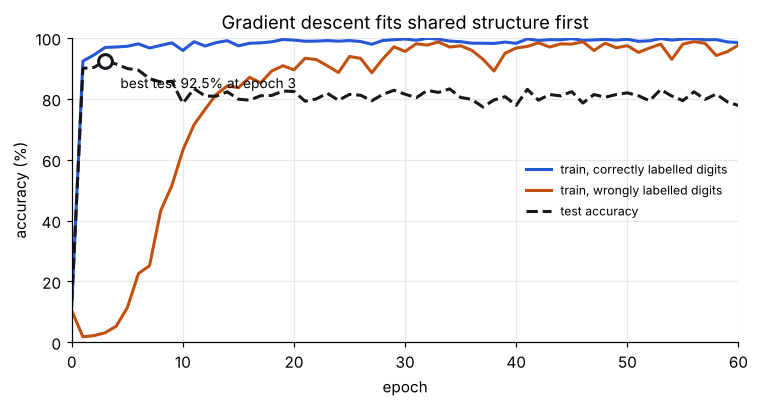

In [18]:
epochs = noisy_history["epoch"]
test_pct = 100 * np.array(noisy_history["test"])
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(epochs, 100 * np.array(noisy_history["clean"]), color=BLUE, label="train, correctly labelled digits")
ax.plot(epochs, 100 * np.array(noisy_history["corrupted"]), color=ORANGE, label="train, wrongly labelled digits")
ax.plot(epochs, test_pct, color=INK, ls="--", label="test accuracy")
ax.plot(epochs[best], test_pct[best], "o", ms=9, mfc="white", mec=INK, mew=2)
ax.annotate(f"best test {test_pct[best]:.1f}% at epoch {epochs[best]}", (epochs[best], test_pct[best]),
            xytext=(10, -18), textcoords="offset points", fontsize=9)
ax.set(title="Gradient descent fits shared structure first", xlabel="epoch", ylabel="accuracy (%)",
       xlim=(0, 60), ylim=(0, 100))
ax.legend(frameon=False, fontsize=8, loc="center right")
plt.tight_layout()
plt.show()

## 9. The edges are almost never trained or tested

**Slides:** *Putting it together: implicit regularization* and *Rethinking generalization* are conceptual (the
latter uses the shifted 7 from section 10). The data slide is *The edges are almost never trained or tested*
("MNIST data is limited to a centered view" on the board). MNIST digits are centred, so the border pixels are almost
always blank. Here: the average of all 10,000 digits, the share of ink inside the central 20 × 20 box, and how many
pixels are blank in every digit. (Over the 8,000 training digits alone the count is 117; see section 11.)

pixels blank in all 10,000 digits: 111
ink inside the central 20x20 box: 96.7%  (outside: 0.03285127878189087)


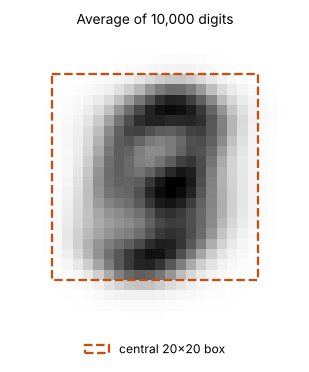

In [19]:
mean_image = X_all.mean(0)
never_inked_all = int((X_all.max(0) == 0).sum())
ink_outside_box = float(1 - X_all.reshape(-1, 28, 28)[:, 4:24, 4:24].sum() / X_all.sum())
print("pixels blank in all 10,000 digits:", never_inked_all)
print(f"ink inside the central 20x20 box: {100 * (1 - ink_outside_box):.1f}%  (outside: {ink_outside_box})")

fig, ax = plt.subplots(figsize=(3.4, 3.4))
show_digit(ax, mean_image, "Average of 10,000 digits")
ax.add_patch(plt.Rectangle((3.5, 3.5), 20, 20, fill=False, ls="--", ec=ORANGE, lw=1.5, label="central 20×20 box"))
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.16), frameon=False, fontsize=8)
plt.show()

## 10. Poll: shift the test set → Stress test results

**Slides:** *Poll: shift the test set* (A ~95%, B ~80%, C ~50%, D ~10%) and *Stress test results*. Three residual
MLPs (seeds 1–3) train for 20 epochs on the ordinary digits and are then tested on the same test digits shifted
right by 0–6 pixels (and, for comparison, shifted down). A random ±2 px shift on both axes (seed 99) is used again in
section 13. The inset follows the first test 7 through the shifts, using the seed-1 model. (Runtime about 30 s.)

*Slide vs. this notebook (mean of 3 seeds, 0–6 px):* slide 95.6, 91.3, 71.8, 45.2, 26.0, 14.1, 8.2%; here 95.7,
91.6, 70.8, 45.8, 27.0, 15.2, 9.4%. Same shape: accuracy halves at 3 px and reaches chance by 6 px.

In [20]:
SHIFTS = list(range(7))
SEEDS = [1, 2, 3]

base_models = []
for seed in SEEDS:
    params = train(init_params(seed), X_train, y_train, seed=seed)
    base_models.append(params)
    print(f"seed {seed}: train {accuracy(params, X_train, y_train)}  test {accuracy(params, X_test, y_test)}")

base_train = [accuracy(params, X_train, y_train) for params in base_models]
base_test = [accuracy(params, X_test, y_test) for params in base_models]
base_right = 100 * np.array([[accuracy(params, shift(X_test, k, 0), y_test) for k in SHIFTS] for params in base_models])
base_down = 100 * np.array([[accuracy(params, shift(X_test, 0, k), y_test) for k in SHIFTS] for params in base_models])
X_test_jitter2 = random_translate(X_test, 2, np.random.default_rng(99))
base_jitter2 = [accuracy(params, X_test_jitter2, y_test) for params in base_models]

print("shift right, mean of 3 seeds (%):", base_right.mean(0).round(1))
print("              min over seeds (%):", base_right.min(0).round(1))
print("              max over seeds (%):", base_right.max(0).round(1))
print("shift down,  mean of 3 seeds (%):", base_down.mean(0).round(1))
print(f"random ±2 px on both axes, mean: {100 * np.mean(base_jitter2):.1f}%")

i7 = int(np.where(y_test == 7)[0][0])           # the first 7 in the test split
seven_predictions = [int(predict(base_models[0], shift(X_test[i7:i7 + 1], k, 0))[0]) for k in SHIFTS]
print("first test 7, shifted 0..6 px right, is predicted as", seven_predictions)

seed 1: train 0.999875  test 0.9585


seed 2: train 0.998875  test 0.9555


seed 3: train 1.0  test 0.9575


shift right, mean of 3 seeds (%): [95.7 91.6 70.8 45.8 27.  15.2  9.4]
              min over seeds (%): [95.6 90.9 70.2 43.8 23.8 13.4  8.2]
              max over seeds (%): [95.9 92.3 71.5 47.1 30.3 17.8 10.1]
shift down,  mean of 3 seeds (%): [95.7 91.3 70.  39.2 17.4  8.   5.6]
random ±2 px on both axes, mean: 72.0%
first test 7, shifted 0..6 px right, is predicted as [7, 7, 7, 3, 0, 0, 5]


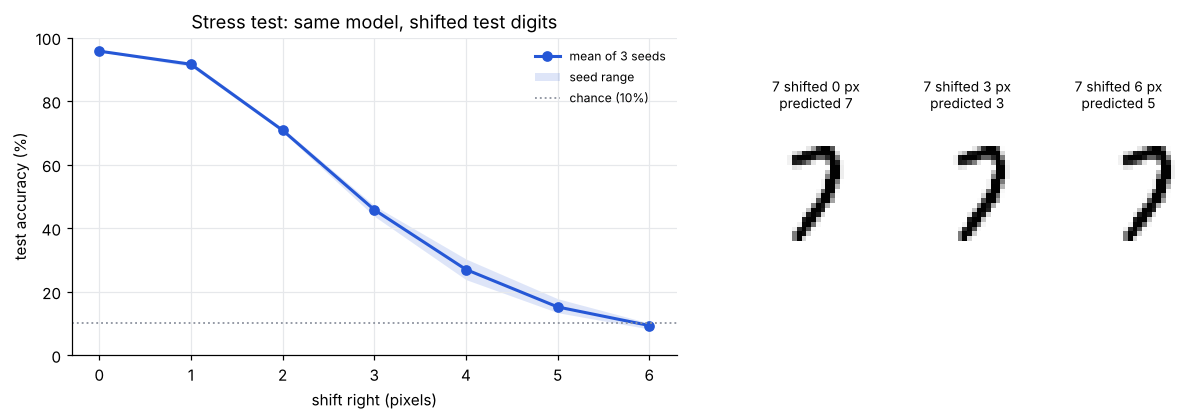

In [21]:
fig = plt.figure(figsize=(11, 3.8))
ax = fig.add_axes([0.06, 0.14, 0.5, 0.76])
ax.plot(SHIFTS, base_right.mean(0), "o-", color=BLUE, label="mean of 3 seeds")
ax.fill_between(SHIFTS, base_right.min(0), base_right.max(0), color=BLUE, alpha=0.15, lw=0, label="seed range")
ax.axhline(10, color=GREY, ls=":", lw=1.2, label="chance (10%)")
ax.set(title="Stress test: same model, shifted test digits", xlabel="shift right (pixels)",
       ylabel="test accuracy (%)", ylim=(0, 100))
ax.legend(frameon=False, fontsize=8)
for j, k in enumerate([0, 3, 6]):
    inset = fig.add_axes([0.62 + j * 0.125, 0.3, 0.11, 0.5])
    show_digit(inset, shift(X_test[i7:i7 + 1], k, 0), f"7 shifted {k} px\npredicted {seven_predictions[k]}",
               vmin=0, vmax=1)
plt.show()

## 11. Why it fails: every weight has an address

**Slide:** *Why it fails*. Each first-layer unit has one weight per pixel, so a row of W0 can be drawn as a 28 × 28
image. The top row shows the 4 units with the largest trained weights (seed-1 baseline). The bottom row shows what
training *changed* (trained minus initial W0) for the 4 units that changed most — this is the slide's figure. A
pixel that never contains ink in training sends zero input, so its weights get (almost) no gradient: whatever the
network learned about a stroke there is tied to the pixels where strokes actually appeared.

*Slide:* 117 of 784 pixels are never inked in the 8,000 training digits; their weights moved by at most 2 × 10⁻⁵,
against up to 0.2 elsewhere. Same here.

In [22]:
W0_init = init_params(1)["W0"]
W0_trained = base_models[0]["W0"]
W0_change = W0_trained - W0_init

largest_units = np.argsort(-np.linalg.norm(W0_trained, axis=1))[:4]
most_changed_units = np.argsort(-np.linalg.norm(W0_change, axis=1))[:4]
print("units with the largest trained weights:", [int(i) for i in largest_units])
print("units whose weights changed most:      ", [int(i) for i in most_changed_units])

never_inked = X_train.max(0) == 0
print("never-inked pixels in the training split:", int(never_inked.sum()))
print("largest |change| on never-inked pixels:", float(np.abs(W0_change[:, never_inked]).max()),
      " anywhere:", float(np.abs(W0_change).max()))

units with the largest trained weights: [120, 12, 47, 158]
units whose weights changed most:       [120, 12, 255, 47]
never-inked pixels in the training split: 117
largest |change| on never-inked pixels: 1.8775463104248047e-05  anywhere: 0.2053665816783905


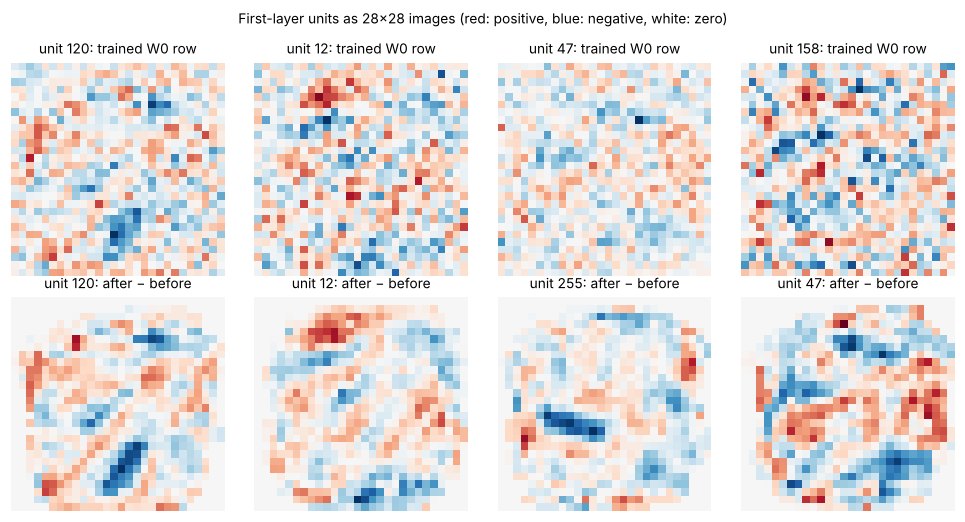

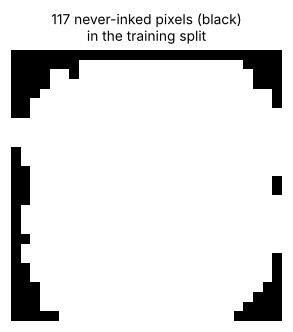

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(9, 4.8))
for ax, unit in zip(axes[0], largest_units):
    limit = np.abs(W0_trained[unit]).max()
    show_digit(ax, W0_trained[unit], f"unit {unit}: trained W0 row", cmap="RdBu_r", vmin=-limit, vmax=limit)
for ax, unit in zip(axes[1], most_changed_units):
    limit = np.abs(W0_change[unit]).max()
    show_digit(ax, W0_change[unit], f"unit {unit}: after − before", cmap="RdBu_r", vmin=-limit, vmax=limit)
fig.suptitle("First-layer units as 28×28 images (red: positive, blue: negative, white: zero)", fontsize=9)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(3.2, 3.2))
show_digit(ax, never_inked, f"{int(never_inked.sum())} never-inked pixels (black)\nin the training split")
plt.show()

## 12. Testing the explanation: shuffle the pixels (and why the accuracy matches)

**Slides:** *Testing the explanation (click Apply)* ("If location doesn't matter, shuffle the pixels") and the hidden
slide *Why the accuracy matches*. If the MLP ignores which pixels are neighbours, then sending every pixel to a fixed
new spot (one permutation, seed 1234, applied to every training and test image) should not hurt it. Three seeds are
retrained on shuffled pixels. The hidden slide makes it exact: starting from W0 with its columns permuted the same way
and using the same batches, the shuffled run computes the same network as the baseline, up to float rounding — which
a chaotic optimizer amplifies over 20 epochs. (Runtime about 1–2 minutes.)

*Slide vs. this notebook:* normal pixels 95.6% (seeds 94.8–96.1%) vs. shuffled 94.7% (94.1–95.7%); here 95.7%
(95.5–95.9%) vs. 95.3% (94.7–95.9%). Hidden slide: float64 weights agree to 10⁻¹⁴ after one epoch and predictions to
96% after 20 epochs; same here.

In [24]:
perm = np.random.default_rng(1234).permutation(784)

perm_models = [train(init_params(seed), X_train, y_train, seed=seed, perm=perm) for seed in SEEDS]
perm_test = [accuracy(params, permute_pixels(X_test, perm), y_test) for params in perm_models]
perm_train = [accuracy(params, permute_pixels(X_train, perm), y_train) for params in perm_models]
print("test accuracy, shuffled pixels:", perm_test, "  normal pixels:", base_test)
print("train accuracy, shuffled pixels:", perm_train)

test accuracy, shuffled pixels: [0.959, 0.9465, 0.9535]   normal pixels: [0.9585, 0.9555, 0.9575]
train accuracy, shuffled pixels: [1.0, 0.993125, 0.999]


In [25]:
def equivalence_check(dtype, epochs, baseline=None):
    """Train the baseline and the pixel-shuffled network from matching starts; compare the results."""
    X_train_d = X_train.astype(dtype)
    X_test_d = X_test.astype(dtype)
    start = {name: w.astype(dtype) for name, w in init_params(1).items()}
    start_permuted = {name: w.copy() for name, w in start.items()}
    start_permuted["W0"] = start_permuted["W0"][:, perm]   # the same weights, reordered like the pixels
    if baseline is None:
        baseline = train(start, X_train_d, y_train, epochs=epochs, seed=1)
    permuted = train(start_permuted, X_train_d, y_train, epochs=epochs, seed=1, perm=perm)
    agree = float((predict(baseline, X_test_d) == predict(permuted, permute_pixels(X_test_d, perm))).mean())
    max_diff = np.abs(baseline["W0"][:, perm] - permuted["W0"]).max()
    print(f"{np.dtype(dtype).name}, {epochs:2d} epochs: predictions agree on {agree} of test digits, "
          f"max |ΔW0| = {max_diff}")


equivalence_check(np.float32, 20, baseline=base_models[0])   # the seed-1 baseline from section 10
equivalence_check(np.float32, 1)
equivalence_check(np.float64, 1)
equivalence_check(np.float64, 20)

float32, 20 epochs: predictions agree on 0.963 of test digits, max |ΔW0| = 0.13763439655303955


float32,  1 epochs: predictions agree on 1.0 of test digits, max |ΔW0| = 1.8139369785785675e-05


float64,  1 epochs: predictions agree on 1.0 of test digits, max |ΔW0| = 9.5513874587283e-15


float64, 20 epochs: predictions agree on 0.963 of test digits, max |ΔW0| = 0.08682353590843908


normal pixels   95.7%  (seeds 95.5-95.9%)
shuffled pixels 95.3%  (seeds 94.7-95.9%)


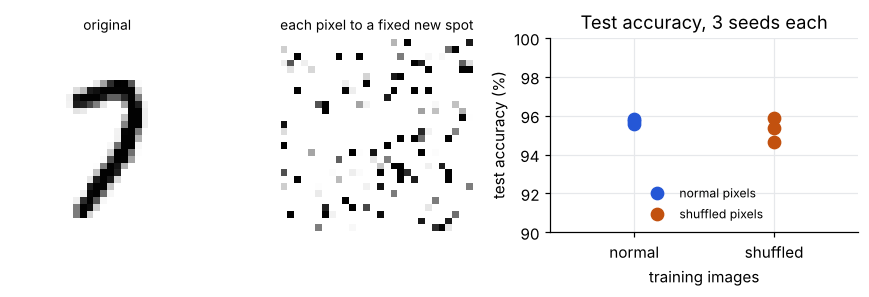

In [26]:
normal_pct = base_right[:, 0]
shuffled_pct = 100 * np.array(perm_test)
print(f"normal pixels   {normal_pct.mean():.1f}%  (seeds {normal_pct.min():.1f}-{normal_pct.max():.1f}%)")
print(f"shuffled pixels {shuffled_pct.mean():.1f}%  (seeds {shuffled_pct.min():.1f}-{shuffled_pct.max():.1f}%)")

fig, axes = plt.subplots(1, 3, figsize=(8, 2.8), gridspec_kw={"width_ratios": [1, 1, 1.6]})
show_digit(axes[0], X_test[i7], "original")
show_digit(axes[1], X_test[i7][perm], "each pixel to a fixed new spot")
axes[2].plot(np.zeros(3), normal_pct, "o", color=BLUE, ms=8, label="normal pixels")
axes[2].plot(np.ones(3), shuffled_pct, "o", color=ORANGE, ms=8, label="shuffled pixels")
axes[2].set(title="Test accuracy, 3 seeds each", xticks=[0, 1], xticklabels=["normal", "shuffled"],
            xlim=(-0.6, 1.6), ylim=(90, 100), xlabel="training images", ylabel="test accuracy (%)")
axes[2].legend(frameon=False, fontsize=8, loc="lower center")
plt.tight_layout()
plt.show()

## 13. Augmentation: the standard fix → Demo: augmented retrain

**Slides:** *Augmentation: the standard fix*, *Augmentation on the map* (conceptual) and *Demo: augmented retrain*.
If the network only knows the positions it was trained on, show it more positions: every training batch is padded
3 px and randomly re-cropped (a fresh shift in [−3, 3] on each axis for every image, every epoch). Seeds 1–3 are
retrained for 20 epochs and the shift test is rerun. Notice that accuracy holds out to 3 px, the range seen in
training, and degrades beyond it. Augmentation also acts as a regularizer: the train/test gap shrinks.
(Runtime about 30 s.)

*Slide vs. this notebook (trained with shifts, 0–6 px):* slide 95.9, 96.1, 95.4, 94.4, 91.7, 80.9, 60.3%; here
96.1, 96.2, 96.0, 95.2, 91.9, 81.1, 58.9%. Random ±2 px: 72 → 96% (here 72.0 → 95.6%); train/test gap 4.2 → 1.6
points (same). The slide's eight randomly shifted 7s are an illustration; their offsets are not reproduced.

In [27]:
aug_models = [train(init_params(seed), X_train, y_train, seed=seed, augment=shift_augment) for seed in SEEDS]
aug_train = [accuracy(params, X_train, y_train) for params in aug_models]
aug_test = [accuracy(params, X_test, y_test) for params in aug_models]
aug_right = 100 * np.array([[accuracy(params, shift(X_test, k, 0), y_test) for k in SHIFTS] for params in aug_models])
aug_down = 100 * np.array([[accuracy(params, shift(X_test, 0, k), y_test) for k in SHIFTS] for params in aug_models])
aug_jitter2 = [accuracy(params, X_test_jitter2, y_test) for params in aug_models]

print("shift right (%), original training:  ", base_right.mean(0).round(1))
print("shift right (%), trained with shifts:", aug_right.mean(0).round(1),
      " min", aug_right.min(0).round(1), " max", aug_right.max(0).round(1))
print("shift down  (%), trained with shifts:", aug_down.mean(0).round(1))
print(f"random ±2 px on both axes: {100 * np.mean(base_jitter2):.1f}% -> {100 * np.mean(aug_jitter2):.2f}%"
      f"  (per seed {np.round(aug_jitter2, 3)})")
base_gap = 100 * (np.mean(base_train) - np.mean(base_test))
aug_gap = 100 * (np.mean(aug_train) - np.mean(aug_test))
print(f"train accuracy {np.mean(base_train):.4f} -> {np.mean(aug_train):.4f}; "
      f"train/test gap {base_gap:.1f} -> {aug_gap:.1f} points")

shift right (%), original training:   [95.7 91.6 70.8 45.8 27.  15.2  9.4]
shift right (%), trained with shifts: [96.1 96.2 96.  95.2 91.9 81.1 58.9]  min [95.8 96.  95.4 94.9 91.7 80.6 55.6]  max [96.4 96.5 96.4 95.8 92.1 81.8 62.5]
shift down  (%), trained with shifts: [96.1 96.  95.3 94.1 89.8 75.9 53.2]
random ±2 px on both axes: 72.0% -> 95.58%  (per seed [0.954 0.955 0.959])
train accuracy 0.9996 -> 0.9770; train/test gap 4.2 -> 1.6 points


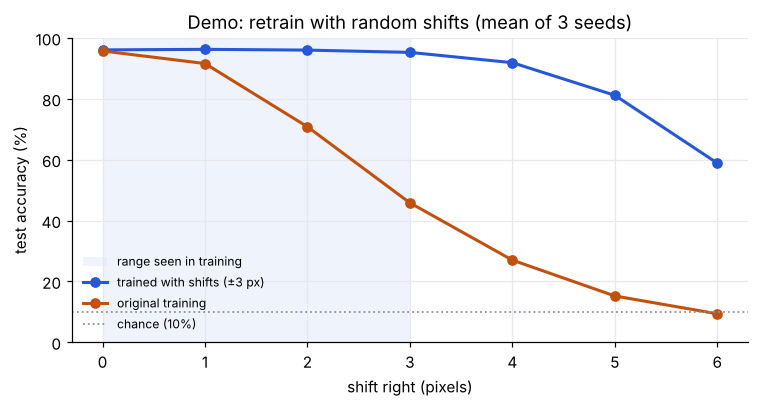

In [28]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.axvspan(0, 3, color="#DCE5FA", alpha=0.45, lw=0, label="range seen in training")
ax.plot(SHIFTS, aug_right.mean(0), "o-", color=BLUE, label="trained with shifts (±3 px)")
ax.plot(SHIFTS, base_right.mean(0), "o-", color=ORANGE, label="original training")
ax.axhline(10, color=GREY, ls=":", lw=1.2, label="chance (10%)")
ax.set(title="Demo: retrain with random shifts (mean of 3 seeds)", xlabel="shift right (pixels)",
       ylabel="test accuracy (%)", ylim=(0, 100))
ax.legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

## 14. What else could change? Scale: same failure, same fix

**Slides:** *What else could change?* is a discussion slide (scale, rotation, stroke thickness, skew). The data slide
is *Scale: same failure, same fix*. Test digits are resized about the image centre from 0.6× to 1.4×. The baseline
models from section 10 are compared with models retrained (seeds 1–3, 20 epochs) on batches in which every image is
rescaled by a random factor in [0.8, 1.2]. The pattern matches the shift test: a sharp drop off the training
distribution for the baseline, and a fix that holds inside the augmented range. (Runtime about 2 minutes.)

*Slide vs. this notebook (mean of 3 seeds, 0.6×–1.4×):* original training: slide 32.4, 52.8, 78.7, 92.7, 95.6, 94.4,
85.9, 72.3, 58.7%; here 32.3, 54.4, 80.5, 93.3, 95.7, 94.4, 85.5, 72.2, 58.1%. Trained with rescaling: slide 70.7,
88.8, 94.3, 95.6, 96.0, 95.7, 95.0, 92.5, 87.0%; here 70.5, 89.2, 94.5, 95.7, 95.5, 95.4, 94.8, 92.7, 87.0%.

In [29]:
SCALES = [0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4]
X_test_scaled = {factor: scale_all(X_test, factor) for factor in SCALES}

scale_base, scale_aug = [], []
for seed, base_params in zip(SEEDS, base_models):
    aug_params = train(init_params(seed), X_train, y_train, seed=seed, augment=scale_augment)
    scale_base.append([accuracy(base_params, X_test_scaled[f], y_test) for f in SCALES])
    scale_aug.append([accuracy(aug_params, X_test_scaled[f], y_test) for f in SCALES])
    print("seed", seed, " original", np.round(scale_base[-1], 3), " augmented", np.round(scale_aug[-1], 3))

scale_base = 100 * np.array(scale_base).mean(0)
scale_aug = 100 * np.array(scale_aug).mean(0)
print("mean, original training (%):", scale_base.round(1))
print("mean, random rescaling  (%):", scale_aug.round(1))

seed 1  original [0.312 0.529 0.801 0.937 0.958 0.942 0.85  0.708 0.566]  augmented [0.709 0.898 0.949 0.962 0.96  0.956 0.954 0.94  0.89 ]


seed 2  original [0.331 0.553 0.796 0.926 0.956 0.941 0.852 0.726 0.586]  augmented [0.687 0.884 0.941 0.951 0.948 0.948 0.942 0.918 0.872]


seed 3  original [0.327 0.549 0.818 0.936 0.958 0.948 0.863 0.732 0.59 ]  augmented [0.72  0.894 0.946 0.958 0.958 0.958 0.949 0.926 0.847]
mean, original training (%): [32.3 54.4 80.5 93.3 95.7 94.4 85.5 72.2 58.1]
mean, random rescaling  (%): [70.5 89.2 94.5 95.7 95.5 95.4 94.8 92.7 87. ]


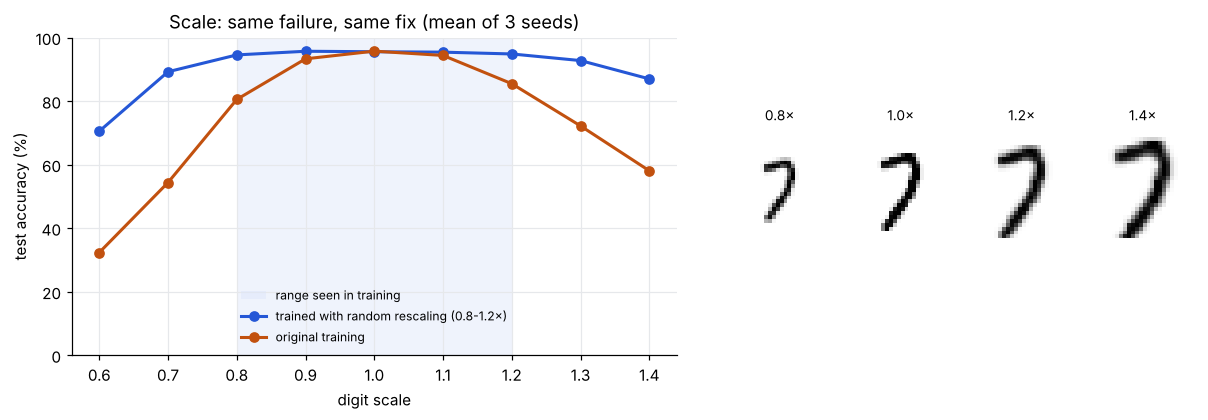

In [30]:
fig = plt.figure(figsize=(11, 3.8))
ax = fig.add_axes([0.06, 0.14, 0.5, 0.76])
ax.axvspan(0.8, 1.2, color="#DCE5FA", alpha=0.45, lw=0, label="range seen in training")
ax.plot(SCALES, scale_aug, "o-", color=BLUE, label="trained with random rescaling (0.8-1.2×)")
ax.plot(SCALES, scale_base, "o-", color=ORANGE, label="original training")
ax.set(title="Scale: same failure, same fix (mean of 3 seeds)", xlabel="digit scale", ylabel="test accuracy (%)",
       ylim=(0, 100))
ax.legend(frameon=False, fontsize=8, loc="lower center")
for j, factor in enumerate([0.8, 1.0, 1.2, 1.4]):
    inset = fig.add_axes([0.6 + j * 0.1, 0.35, 0.09, 0.4])
    show_digit(inset, np.clip(scale(X_test[i7], factor), 0, 1), f"{factor}×")
plt.show()

## 15. The remaining slides

- **Should we add flips?** A real 7, 3, 4 and 8 beside their mirror images ("not a 7", "not a 3", "not a 4",
  "still an 8"). An illustration; the four digits were picked by hand.
- **Label safety and costs.** A multiplication: 60,000 MNIST training images × 49 shifts (−3 to +3 px on each axis)
  × 5 scales (0.8–1.2) × 7 rotations (−15° to +15° in 5° steps), then × 3 stroke widths. The robustness numbers it
  repeats (94% at 3 px, 60% at 6 px, 87% at 1.4×) are the slide values from sections 13 and 14.
- **Your project**, **Not overfitting: the wrong solution**, **Why CIFAR-10 and ImageNet are harder** and
  **Cliffhanger** are text and diagrams only.

In [31]:
versions_per_digit = 49 * 5 * 7
print(f"{versions_per_digit:,} versions per digit; x 60,000 = {60000 * versions_per_digit:.1e}; "
      f"with 3 stroke widths {3 * 60000 * versions_per_digit:.1e}")

1,715 versions per digit; x 60,000 = 1.0e+08; with 3 stroke widths 3.1e+08
